In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
data = pd.read_csv("data/Absenteeism_at_work.csv")

In [4]:
data.head()

,ID,Reason for absence,Month of absence,Day of the week,Seasons,Transportation expense,Distance from Residence to Work,Service time,Age,Work load Average/day,...,Disciplinary failure,Education,Son,Social drinker,Social smoker,Pet,Weight,Height,Body mass index,Absenteeism time in hours
0,11,26,7,3,1,289,36,13,33,239.554,...,0,1,2,1,0,1,90,172,30,4
1,36,0,7,3,1,118,13,18,50,239.554,...,1,1,1,1,0,0,98,178,31,0
2,3,23,7,4,1,179,51,18,38,239.554,...,0,1,0,1,0,0,89,170,31,2
3,7,7,7,5,1,279,5,14,39,239.554,...,0,1,2,1,1,0,68,168,24,4
4,11,23,7,5,1,289,36,13,33,239.554,...,0,1,2,1,0,1,90,172,30,2


In [5]:
import pandas_profiling

In [6]:
pandas_profiling.ProfileReport(data)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|█████████████████████████████████████████████████████████████████████████████████| 21/21 [00:00<00:00, 887.66it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 740 entries, 0 to 739
Data columns (total 21 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   ID                               740 non-null    int64  
 1   Reason for absence               740 non-null    int64  
 2   Month of absence                 740 non-null    int64  
 3   Day of the week                  740 non-null    int64  
 4   Seasons                          740 non-null    int64  
 5   Transportation expense           740 non-null    int64  
 6   Distance from Residence to Work  740 non-null    int64  
 7   Service time                     740 non-null    int64  
 8   Age                              740 non-null    int64  
 9   Work load Average/day            740 non-null    float64
 10  Hit target                       740 non-null    int64  
 11  Disciplinary failure             740 non-null    int64  
 12  Education             

In [8]:
data.isnull().sum()

ID                                 0
Reason for absence                 0
Month of absence                   0
Day of the week                    0
Seasons                            0
Transportation expense             0
Distance from Residence to Work    0
Service time                       0
Age                                0
Work load Average/day              0
Hit target                         0
Disciplinary failure               0
Education                          0
Son                                0
Social drinker                     0
Social smoker                      0
Pet                                0
Weight                             0
Height                             0
Body mass index                    0
Absenteeism time in hours          0
dtype: int64

array([[<Axes: title={'center': 'ID'}>,
        <Axes: title={'center': 'Reason for absence'}>,
        <Axes: title={'center': 'Month of absence'}>,
        <Axes: title={'center': 'Day of the week'}>,
        <Axes: title={'center': 'Seasons'}>],
       [<Axes: title={'center': 'Transportation expense'}>,
        <Axes: title={'center': 'Distance from Residence to Work'}>,
        <Axes: title={'center': 'Service time'}>,
        <Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Work load Average/day '}>],
       [<Axes: title={'center': 'Hit target'}>,
        <Axes: title={'center': 'Disciplinary failure'}>,
        <Axes: title={'center': 'Education'}>,
        <Axes: title={'center': 'Son'}>,
        <Axes: title={'center': 'Social drinker'}>],
       [<Axes: title={'center': 'Social smoker'}>,
        <Axes: title={'center': 'Pet'}>,
        <Axes: title={'center': 'Weight'}>,
        <Axes: title={'center': 'Height'}>,
        <Axes: title={'center': 'Body mass 

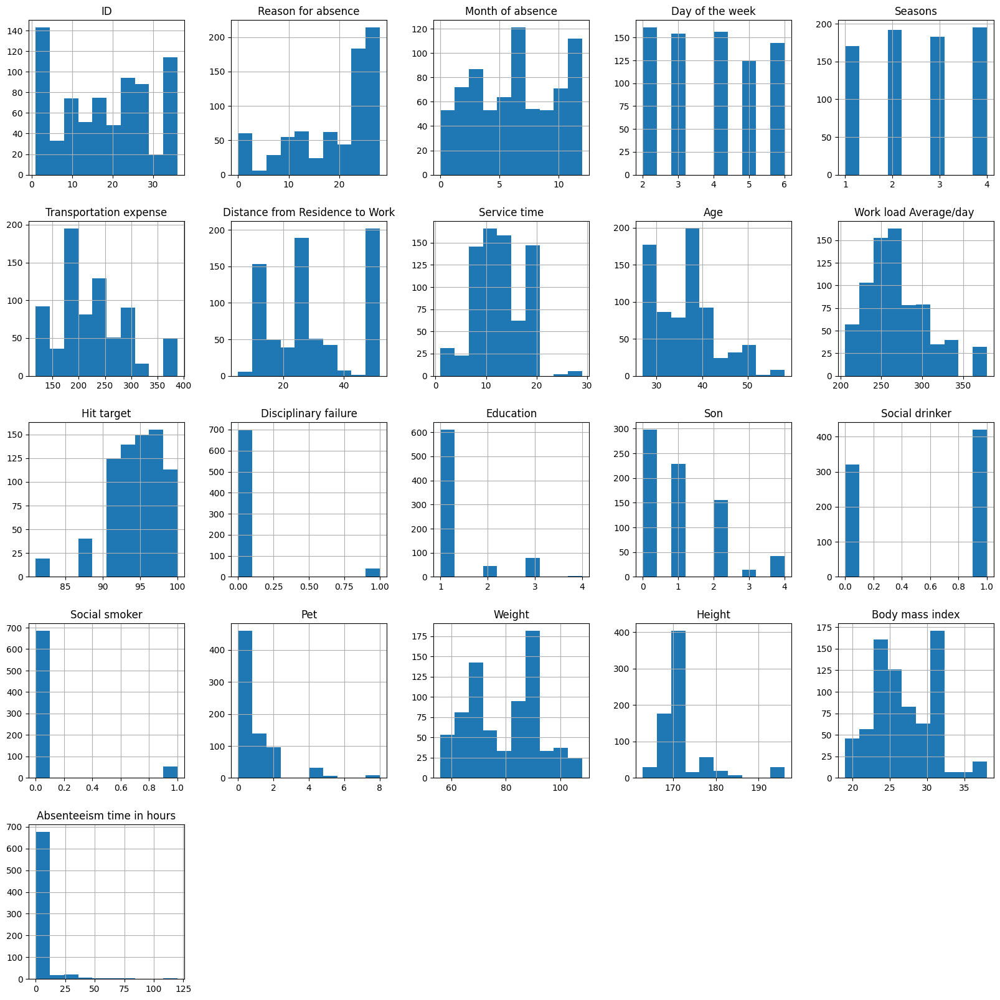

In [9]:
data.hist(figsize=(20, 20))

In [39]:
numerical = [ 'Age', 'Body mass index', 
             'Distance from Residence to Work', 'Height', 'Hit target',
             'Service time', 'Transportation expense', 'Weight', 'Work load Average/day '
            ]
categorical = [col for col in data.columns if col not in numerical]

In [ ]:
data.drop(['ID'], axis=1, inplace=True)

In [22]:
data.columns

Index(['Reason for absence', 'Month of absence', 'Day of the week', 'Seasons',
       'Transportation expense', 'Distance from Residence to Work',
       'Service time', 'Age', 'Work load Average/day ', 'Hit target',
       'Disciplinary failure', 'Education', 'Son', 'Social drinker',
       'Social smoker', 'Pet', 'Weight', 'Height', 'Body mass index',
       'Absenteeism time in hours'],
      dtype='object')

In [23]:
numerical

['Absenteeism time in hours',
 'Age',
 'Body mass index',
 'Distance from Residence to Work',
 'Height',
 'Hit target',
 'Service time',
 'Transportation expense',
 'Weight',
 'Work load Average/day ']

In [24]:
categorical

['Reason for absence',
 'Month of absence',
 'Day of the week',
 'Seasons',
 'Disciplinary failure',
 'Education',
 'Son',
 'Social drinker',
 'Social smoker',
 'Pet']

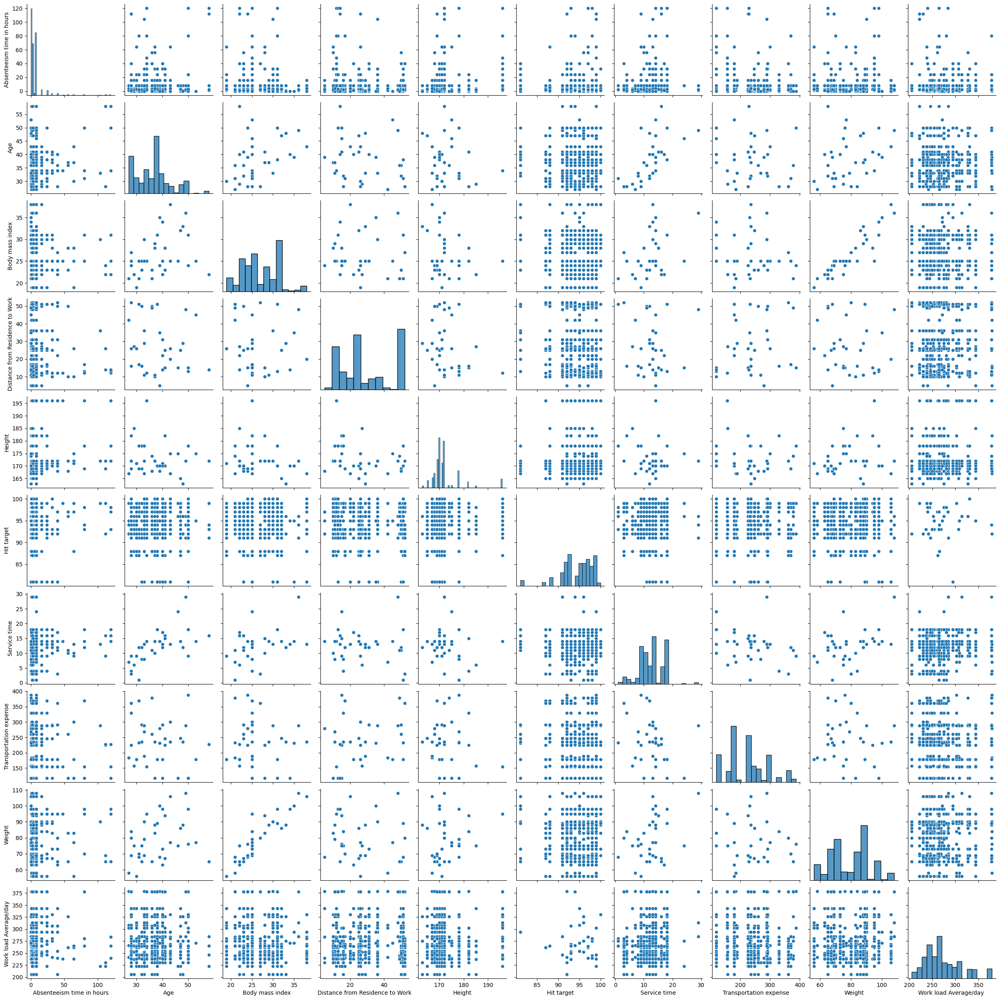

In [25]:
sns.pairplot(data[numerical])

<Axes: >

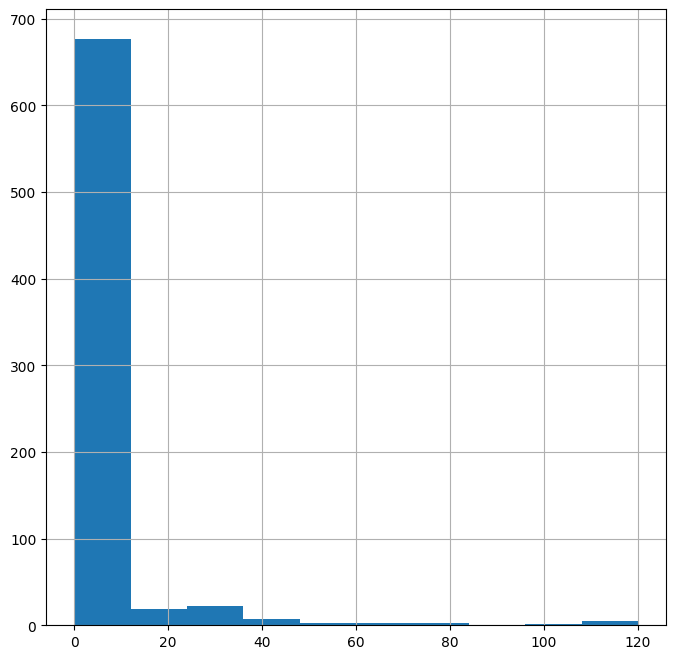

In [26]:
plt.figure(figsize=(8,8))
data['Absenteeism time in hours'].hist()

<Axes: >

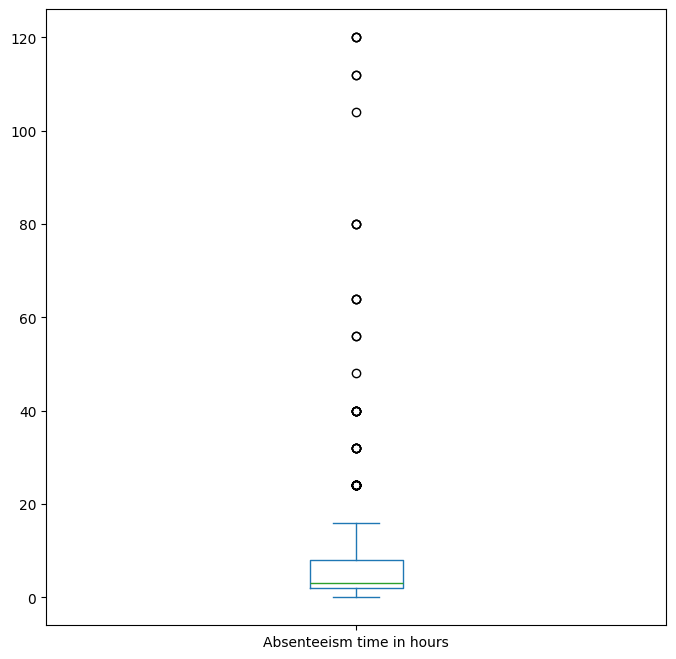

In [30]:
plt.figure(figsize=(8,8))
data['Absenteeism time in hours'].plot.box()

<Axes: >

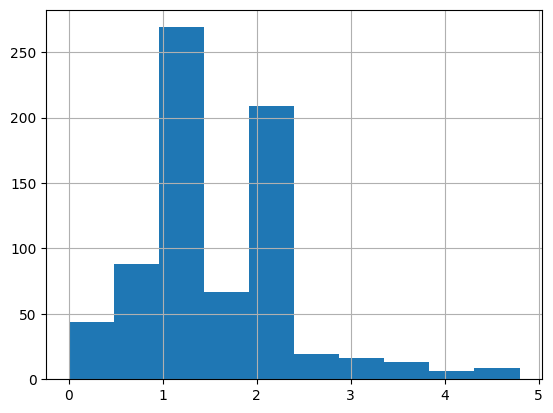

In [32]:
(data['Absenteeism time in hours']+1).apply(np.log).hist()

## Убираем выбросы целевой

In [34]:
data = data[data['Absenteeism time in hours'] <= 60]

<Axes: >

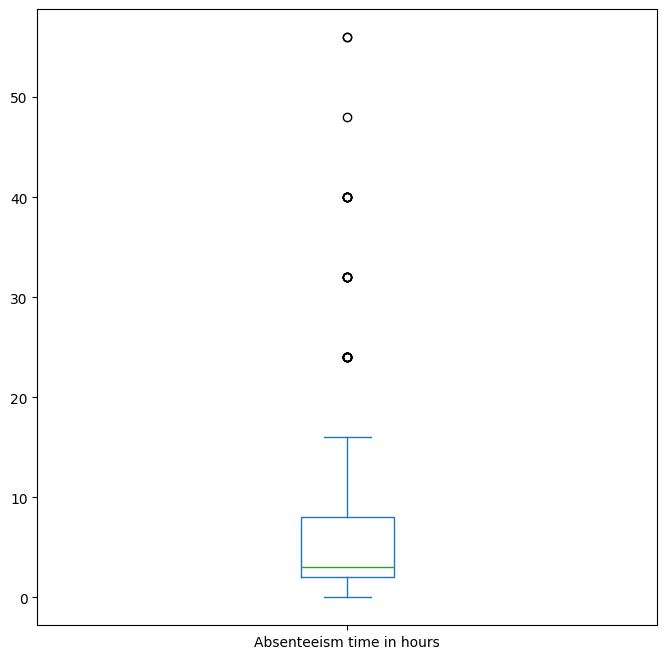

In [35]:
plt.figure(figsize=(8,8))
data['Absenteeism time in hours'].plot.box()

<Axes: >

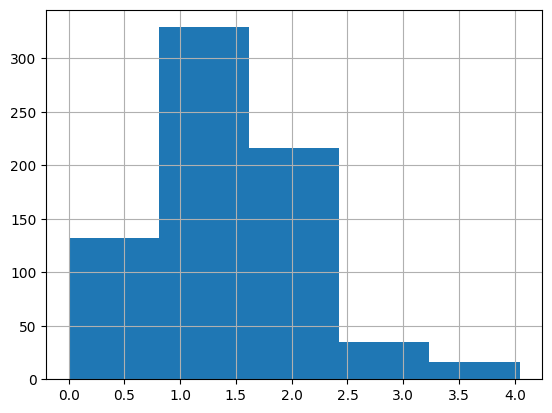

In [37]:
(data['Absenteeism time in hours']+1).apply(np.log).hist(bins=5)

In [38]:
data['Absenteeism time in hours'] = (data['Absenteeism time in hours']+1).apply(np.log)

## Категориальные переменные

In [43]:
data[categorical]

,Reason for absence,Month of absence,Day of the week,Seasons,Disciplinary failure,Education,Son,Social drinker,Social smoker,Pet,Absenteeism time in hours
0,26,7,3,1,0,1,2,1,0,1,1.609438
1,0,7,3,1,1,1,1,1,0,0,0.000000
2,23,7,4,1,0,1,0,1,0,0,1.098612
3,7,7,5,1,0,1,2,1,1,0,1.609438
4,23,7,5,1,0,1,2,1,0,1,1.098612
...,...,...,...,...,...,...,...,...,...,...,...
735,14,7,3,1,0,1,2,1,0,1,2.197225
736,11,7,3,1,0,3,1,0,0,1,1.609438
737,0,0,3,1,0,1,1,1,0,8,0.000000
738,0,0,4,2,0,1,2,1,0,2,0.000000


<Axes: ylabel='Reason for absence'>

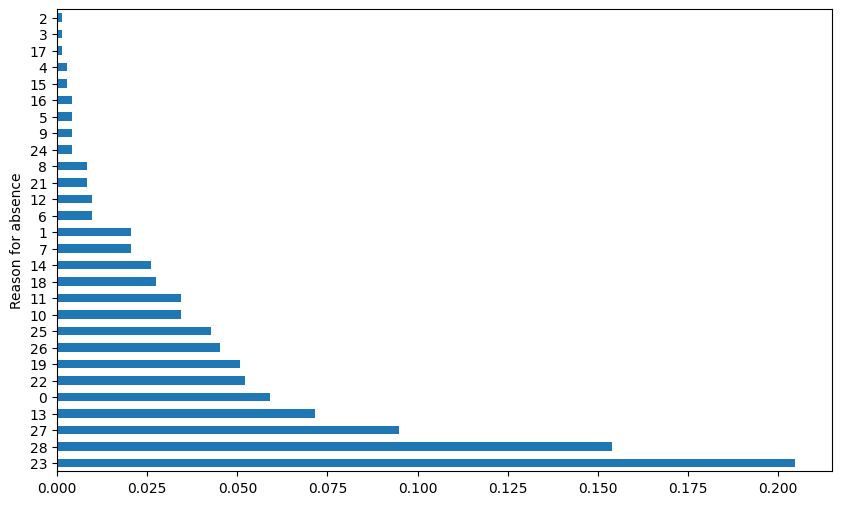

In [45]:
data['Reason for absence'].value_counts(normalize=True).plot.barh(figsize=(10, 6))

In [46]:
data.shape

(728, 20)

## Частотное кодирование категориальных переменных
Полезно, когда в категории слишком много уникальных значений

In [47]:
data['Reason for absence'].value_counts(normalize=True)

Reason for absence
23    0.204670
28    0.153846
27    0.094780
13    0.071429
0     0.059066
22    0.052198
19    0.050824
26    0.045330
25    0.042582
10    0.034341
11    0.034341
18    0.027473
14    0.026099
7     0.020604
1     0.020604
6     0.009615
12    0.009615
21    0.008242
8     0.008242
24    0.004121
9     0.004121
5     0.004121
16    0.004121
15    0.002747
4     0.002747
17    0.001374
3     0.001374
2     0.001374
Name: proportion, dtype: float64

In [49]:
data['Reason for absence'].value_counts(normalize=True)[:5]

Reason for absence
23    0.204670
28    0.153846
27    0.094780
13    0.071429
0     0.059066
Name: proportion, dtype: float64

In [50]:
stay = [0, 27, 13, 28, 23]

In [52]:
data['Reason for absence'] = data['Reason for absence'].apply(lambda x: x if x in stay else -1)

<Axes: xlabel='Reason for absence'>

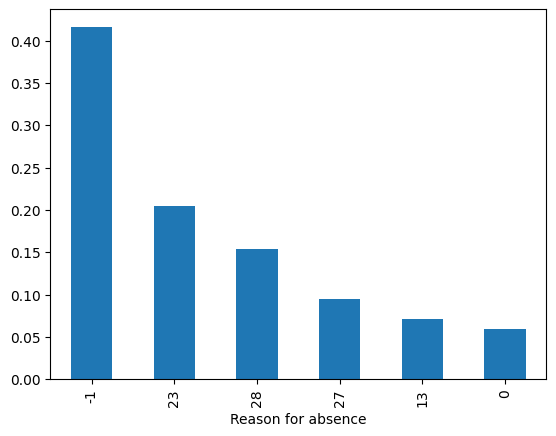

In [53]:
data['Reason for absence'].value_counts(normalize=True).plot.bar()

In [54]:
data[categorical]

,Reason for absence,Month of absence,Day of the week,Seasons,Disciplinary failure,Education,Son,Social drinker,Social smoker,Pet,Absenteeism time in hours
0,-1,7,3,1,0,1,2,1,0,1,1.609438
1,0,7,3,1,1,1,1,1,0,0,0.000000
2,23,7,4,1,0,1,0,1,0,0,1.098612
3,-1,7,5,1,0,1,2,1,1,0,1.609438
4,23,7,5,1,0,1,2,1,0,1,1.098612
...,...,...,...,...,...,...,...,...,...,...,...
735,-1,7,3,1,0,1,2,1,0,1,2.197225
736,-1,7,3,1,0,3,1,0,0,1,1.609438
737,0,0,3,1,0,1,1,1,0,8,0.000000
738,0,0,4,2,0,1,2,1,0,2,0.000000


<Axes: ylabel='Month of absence'>

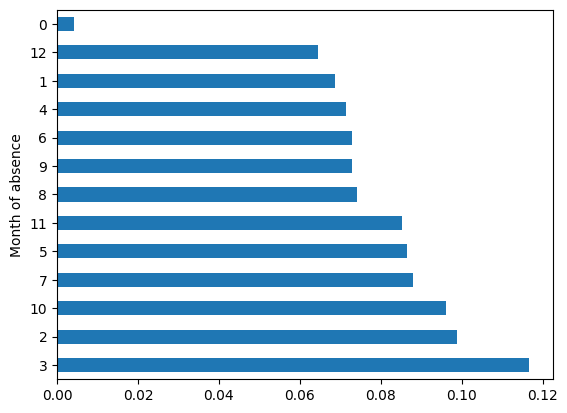

In [55]:
data['Month of absence'].value_counts(normalize=True).plot.barh()

<Axes: ylabel='Seasons'>

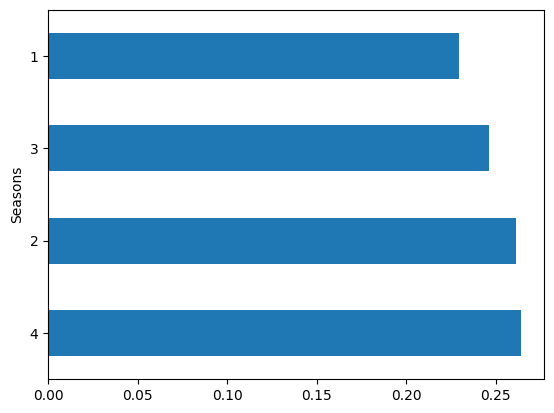

In [56]:
data['Seasons'].value_counts(normalize=True).plot.barh()

In [57]:
data.drop(['Month of absence'], axis=1, inplace=True)

## Работа с непрерывными

In [41]:
from sklearn.model_selection import train_test_split

In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    data.drop(['Absenteeism time in hours'], axis=1),
    data['Absenteeism time in hours'],
    test_size=0.3
)

In [40]:
data[numerical]

,Age,Body mass index,Distance from Residence to Work,Height,Hit target,Service time,Transportation expense,Weight,Work load Average/day
0,33,30,36,172,97,13,289,90,239.554
1,50,31,13,178,97,18,118,98,239.554
2,38,31,51,170,97,18,179,89,239.554
3,39,24,5,168,97,14,279,68,239.554
4,33,30,36,172,97,13,289,90,239.554
...,...,...,...,...,...,...,...,...,...
735,33,30,36,172,93,13,289,90,264.604
736,37,29,11,172,93,14,235,88,264.604
737,40,34,14,170,95,13,118,98,271.219
738,39,35,35,170,95,14,231,100,271.219
